# Predicción de precios de vehículos usados

Desarrollé una comparación de modelos para estimar el precio anunciado de vehículos de Rusty Bargain, considerando el error y el tiempo de cálculo. Proyecto académico del bootcamp de Data Science de TripleTen.

**Luis Eduardo Aguilar Castellanos** · Python · pandas · scikit-learn · LightGBM · CatBoost

## Problema y evaluación

El objetivo es estimar precios en euros a partir de las características del vehículo. Reservé 20 % para prueba y utilicé el 20 % para validación y el 60 % para entrenamiento. Seleccioné la configuración con menor RMSE de validación y la ajusté sobre entrenamiento y validación antes de medir su error final. Las particiones son aleatorias; no representan una evaluación de precios futuros.

In [1]:
from pathlib import Path
import os, json, time, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
ROOT = Path.cwd()
for folder in ['reports', 'assets']: (ROOT / folder).mkdir(exist_ok=True)
DATA = Path(os.environ.get('CAR_DATA_PATH', str(ROOT / 'data/car_data.csv')))
if not DATA.is_file(): raise FileNotFoundError('Configura CAR_DATA_PATH o coloca car_data.csv en data/.')
raw = pd.read_csv(DATA)
print('Anuncios de entrada:', len(raw))


Anuncios de entrada: 354369


## Datos y preparación

Utilicé año de matriculación, potencia, kilometraje y seis características categóricas. Eliminé duplicados de las variables analíticas y limité el alcance a precios entre 100 y 20 000 EUR, años entre 1910 y 2016 y potencias entre 20 y 1000 CV. Los valores categóricos ausentes representan información desconocida.

Para evitar que una combinación idéntica de características aparezca en distintas particiones, mantuve sus anuncios en un mismo grupo, aunque sus precios difieran. Los transformadores se ajustan exclusivamente con la partición de entrenamiento correspondiente.

In [2]:
mapping = {'Price':'price','VehicleType':'vehicle_type','RegistrationYear':'registration_year',
 'Gearbox':'gearbox','Power':'power','Model':'model','Mileage':'mileage',
 'FuelType':'fuel_type','Brand':'brand','NotRepaired':'not_repaired'}
df = raw[list(mapping)].rename(columns=mapping).drop_duplicates().copy()
n_unique = len(df)
df = df[df.price.between(100,20000) & df.registration_year.between(1910,2016) & df.power.between(20,1000)].copy()
cats = ['vehicle_type','gearbox','model','fuel_type','brand','not_repaired']
nums = ['registration_year','power','mileage']
df[cats] = df[cats].fillna('unknown').astype(str)
X, y = df[cats+nums], df.price
from sklearn.model_selection import GroupShuffleSplit
groups = pd.util.hash_pandas_object(X, index=False).values
trainval_idx, test_idx = next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=42).split(X,y,groups))
train_rel, val_rel = next(GroupShuffleSplit(n_splits=1,test_size=.25,random_state=42).split(X.iloc[trainval_idx],y.iloc[trainval_idx],groups[trainval_idx]))
train_idx, val_idx = trainval_idx[train_rel], trainval_idx[val_rel]
for a,b in [(train_idx,val_idx),(train_idx,test_idx),(val_idx,test_idx)]:
    assert not set(groups[a]) & set(groups[b])
summary = {'input':len(raw),'unique_rows':n_unique,'retained':len(df),
 'train':len(train_idx),'validation':len(val_idx),'test':len(test_idx)}
print(pd.Series(summary).to_string())
pd.Series(summary,name='rows').to_csv(ROOT/'reports/data_summary.csv')


input          354369
unique_rows    309329
retained       256069
train          153396
validation      50914
test            51759


In [3]:
def make_model(kind, params):
    if kind == 'CatBoost':
        return CatBoostRegressor(random_seed=12345,verbose=False,thread_count=1,
            allow_writing_files=False,cat_features=cats,**params)
    if kind == 'LightGBM':
        return LGBMRegressor(random_state=12345,n_jobs=1,**params)
    estimators = {'Regresión lineal':LinearRegression,
                  'Árbol':DecisionTreeRegressor,'Random Forest':RandomForestRegressor}
    prep = ColumnTransformer([('num',StandardScaler(),nums),
        ('cat',OneHotEncoder(handle_unknown='ignore'),cats)])
    options = {} if kind=='Regresión lineal' else {'random_state':12345}
    if kind=='Random Forest': options['n_jobs']=1
    return Pipeline([('features',prep),('model',estimators[kind](**options,**params))])

def inputs(kind, fit_X, predict_X):
    fit_X, predict_X = fit_X.copy(), predict_X.copy()
    if kind == 'LightGBM':
        for col in cats:
            dtype = pd.CategoricalDtype(categories=sorted(fit_X[col].unique()))
            fit_X[col] = fit_X[col].astype(dtype)
            predict_X[col] = predict_X[col].astype(dtype)
    return fit_X, predict_X

configs = [('Regresión lineal',{}),('Árbol',{'max_depth':5}),('Árbol',{'max_depth':12}),
 ('Random Forest',{'n_estimators':20,'max_depth':8}),
 ('Random Forest',{'n_estimators':50,'max_depth':12}),
 ('LightGBM',{'n_estimators':100,'learning_rate':.1,'max_depth':10}),
 ('LightGBM',{'n_estimators':200,'learning_rate':.05,'max_depth':15}),
 ('CatBoost',{'iterations':150,'learning_rate':.1,'depth':6}),
 ('CatBoost',{'iterations':300,'learning_rate':.08,'depth':8})]
rows=[]
for i,(kind,params) in enumerate(configs):
    model = make_model(kind,params)
    start = time.perf_counter()
    fit_X, val_X = inputs(kind,X.iloc[train_idx],X.iloc[val_idx])
    model.fit(fit_X,y.iloc[train_idx])
    fit_seconds = time.perf_counter()-start
    start = time.perf_counter()
    pred = model.predict(val_X)
    predict_seconds = time.perf_counter()-start
    rows.append({'config':i,'model':kind,'parameters':json.dumps(params),
       'rmse_eur':float(mean_squared_error(y.iloc[val_idx],pred)**.5),
       'fit_seconds':fit_seconds,'prediction_seconds':predict_seconds})
    print(kind,params,round(rows[-1]['rmse_eur'],2),flush=True)
comparison = pd.DataFrame(rows).sort_values('rmse_eur')
comparison.to_csv(ROOT/'reports/validation_comparison.csv',index=False)
display(comparison)


Regresión lineal {} 2667.27


Árbol {'max_depth': 5} 2442.31


Árbol {'max_depth': 12} 1980.84


Random Forest {'n_estimators': 20, 'max_depth': 8} 2049.22


Random Forest {'n_estimators': 50, 'max_depth': 12} 1828.4


LightGBM {'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 10} 1632.28


LightGBM {'n_estimators': 200, 'learning_rate': 0.05, 'max_depth': 15} 1628.74


CatBoost {'iterations': 150, 'learning_rate': 0.1, 'depth': 6} 1728.5


CatBoost {'iterations': 300, 'learning_rate': 0.08, 'depth': 8} 1639.35


,config,model,parameters,rmse_eur,fit_seconds,prediction_seconds
6,6,LightGBM,"{""n_estimators"": 200, ""learning_rate"": 0.05, ""...",1628.743477,2.036176,1.099935
5,5,LightGBM,"{""n_estimators"": 100, ""learning_rate"": 0.1, ""m...",1632.284230,1.190881,0.504138
8,8,CatBoost,"{""iterations"": 300, ""learning_rate"": 0.08, ""de...",1639.349385,103.983882,0.141964
7,7,CatBoost,"{""iterations"": 150, ""learning_rate"": 0.1, ""dep...",1728.501224,18.322623,0.138217
4,4,Random Forest,"{""n_estimators"": 50, ""max_depth"": 12}",1828.397869,139.890485,0.297155
2,2,Árbol,"{""max_depth"": 12}",1980.838761,4.055384,0.090811
3,3,Random Forest,"{""n_estimators"": 20, ""max_depth"": 8}",2049.220969,19.558535,0.150028
1,1,Árbol,"{""max_depth"": 5}",2442.308721,0.627109,0.086298
0,0,Regresión lineal,{},2667.266101,3.568132,0.094072


## Evaluación final

Elegí el menor RMSE de validación entre nueve configuraciones. Comparé el modelo seleccionado con regresión lineal sobre los mismos anuncios de prueba. Los tiempos dependen del equipo y del volumen de datos: medí un ajuste por configuración, con un hilo en los ensambles; el tiempo de ajuste incluye la preparación de categorías y el preprocesamiento del modelo. La predicción mide el cálculo sobre la entrada ya preparada para LightGBM.

In [4]:
best_id = int(comparison.iloc[0]['config'])
kind,params = configs[best_id]
test_rows=[]
predictions={}
for label,options in [(kind,params),('Regresión lineal',{})]:
    if label in predictions: continue
    model = make_model(label,options)
    fit_X,test_X = inputs(label,X.iloc[trainval_idx],X.iloc[test_idx])
    model.fit(fit_X,y.iloc[trainval_idx])
    pred = model.predict(test_X)
    predictions[label]=pred
    test_rows.append({'model':label,'rmse_eur':float(mean_squared_error(y.iloc[test_idx],pred)**.5),
                     'mae_eur':float(mean_absolute_error(y.iloc[test_idx],pred))})
test_results=pd.DataFrame(test_rows)
test_results.to_csv(ROOT/'reports/test_comparison.csv',index=False)
metrics={'selected_model':kind,'parameters':params,'validation_rmse_eur':float(comparison.iloc[0].rmse_eur),
 'test':test_rows,'data':summary,'python':platform.python_version(),
 'split':'GroupShuffleSplit: 60/20/20 de grupos de características, semillas 42',
 'selection':'Menor RMSE de validación entre nueve configuraciones',
 'relative_rmse_reduction':1-test_rows[0]['rmse_eur']/test_rows[-1]['rmse_eur']}
(ROOT/'reports/metrics.json').write_text(json.dumps(metrics,ensure_ascii=False,indent=2),encoding='utf-8')
display(test_results)


,model,rmse_eur,mae_eur
0,LightGBM,1639.698521,1038.427781
1,Regresión lineal,2654.510958,1843.600374


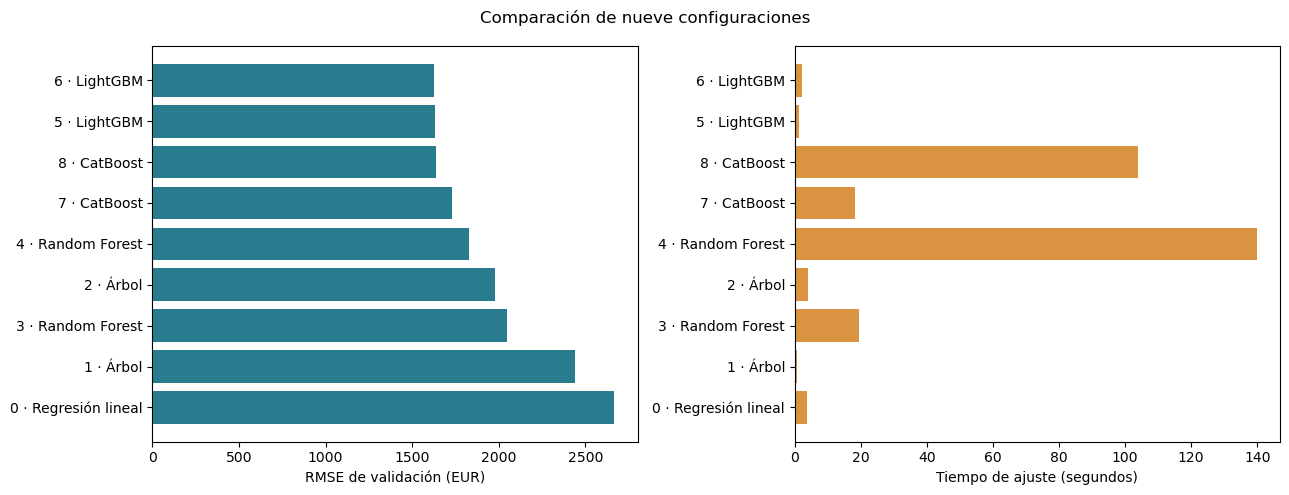

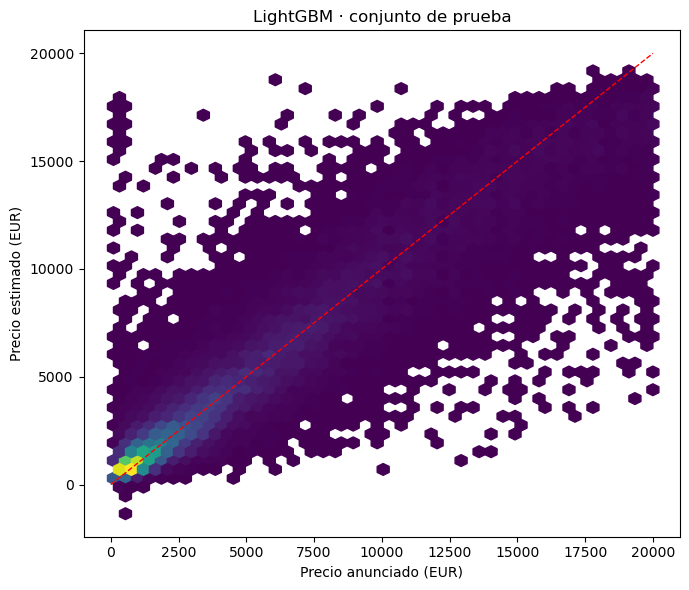

In [5]:
fig,axes=plt.subplots(1,2,figsize=(13,5))
labels=[str(int(r.config))+' · '+r.model for r in comparison.itertuples()]
axes[0].barh(labels,comparison.rmse_eur,color='#287c8e')
axes[0].invert_yaxis(); axes[0].set_xlabel('RMSE de validación (EUR)')
axes[1].barh(labels,comparison.fit_seconds,color='#da9340')
axes[1].invert_yaxis(); axes[1].set_xlabel('Tiempo de ajuste (segundos)')
fig.suptitle('Comparación de nueve configuraciones'); fig.tight_layout()
fig.savefig(ROOT/'assets/comparacion_modelos.png',dpi=150,bbox_inches='tight'); plt.show()
fig,ax=plt.subplots(figsize=(7,6))
ax.hexbin(y.iloc[test_idx],predictions[kind],gridsize=45,mincnt=1,cmap='viridis')
ax.plot([0,20000],[0,20000],'r--',linewidth=1)
ax.set(xlabel='Precio anunciado (EUR)',ylabel='Precio estimado (EUR)',title=kind+' · conjunto de prueba')
fig.tight_layout(); fig.savefig(ROOT/'assets/predicciones.png',dpi=150); plt.show()


## Alcance y limitaciones

Estimo precios anunciados, no precios de venta confirmados. Los filtros excluyen parte del mercado; por tanto, el desempeño se refiere a los anuncios retenidos. Agrupar especificaciones idénticas reduce su solapamiento, pero no permite identificar vehículos reales sin un identificador individual. La separación aleatoria tampoco mide cambios del mercado a lo largo del tiempo.

El RMSE está expresado en euros y penaliza especialmente los errores grandes. Su reducción frente a una referencia no equivale a un porcentaje de ahorro ni a un error relativo por vehículo. Una aplicación comercial requeriría datos recientes, evaluación temporal y seguimiento del error por segmento.